# Histograms, Binnings, and Density

A simple histogram can be a great first step in understanding a dataset. Earlier, we saw a preview of Matplotlib's histogram function, which creates a basic histogram in one line, once the normal boiler-plate imports are done:



In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

data = np.random.randn(1000)

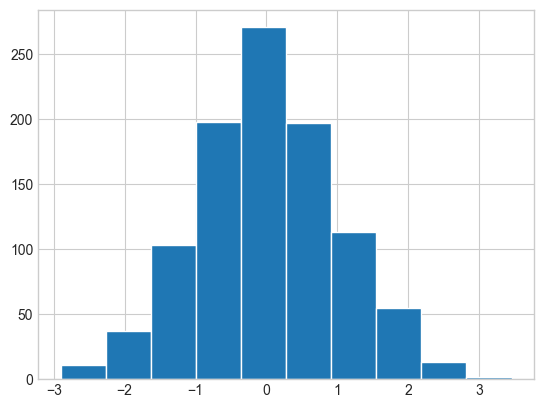

In [2]:
plt.hist(data);

The **hist()** function has many options to tune both the calculation and the display; here's an example of a more customized histogram:



(array([0.01414954, 0.01414954, 0.02358257, 0.03773211, 0.0707477 ,
        0.06603119, 0.08961375, 0.1414954 , 0.25469172, 0.22167612,
        0.34902198, 0.36317152, 0.43391922, 0.3914706 , 0.45278528,
        0.33487244, 0.30185685, 0.29242382, 0.2122431 , 0.19809356,
        0.12262935, 0.13677889, 0.09904678, 0.02358257, 0.02358257,
        0.03301559, 0.00471651, 0.00471651, 0.        , 0.00471651]),
 array([-2.90312806, -2.69110703, -2.479086  , -2.26706497, -2.05504394,
        -1.84302292, -1.63100189, -1.41898086, -1.20695983, -0.9949388 ,
        -0.78291777, -0.57089674, -0.35887571, -0.14685468,  0.06516635,
         0.27718738,  0.4892084 ,  0.70122943,  0.91325046,  1.12527149,
         1.33729252,  1.54931355,  1.76133458,  1.97335561,  2.18537664,
         2.39739767,  2.6094187 ,  2.82143973,  3.03346075,  3.24548178,
         3.45750281]),
 [<matplotlib.patches.Polygon at 0x28d8c5c34d0>])

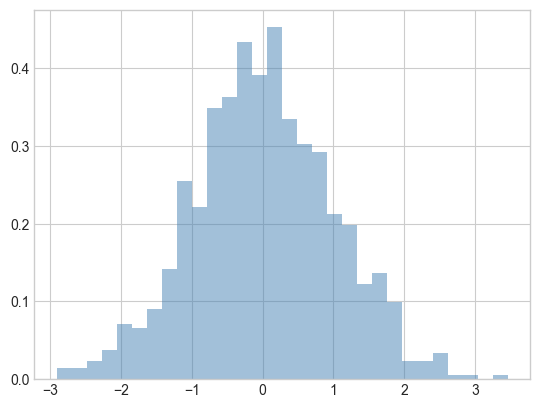

In [7]:
plt.hist(
    data,                  # Your array of values
    bins=30,               # Divide into 30 intervals
    density=True,          # Normalize to show probability density
    alpha=0.5,             # 50% transparency
    histtype='stepfilled', # Filled histogram with outlined edges
    color='steelblue',     # Fill color
    edgecolor='none'       # No border around bars
)

The **plt.hist** docstring has more information on other customization options available. I find this combination of **histtype='stepfilled'** along with some transparency **alpha** to be very useful when comparing histograms of several distributions:

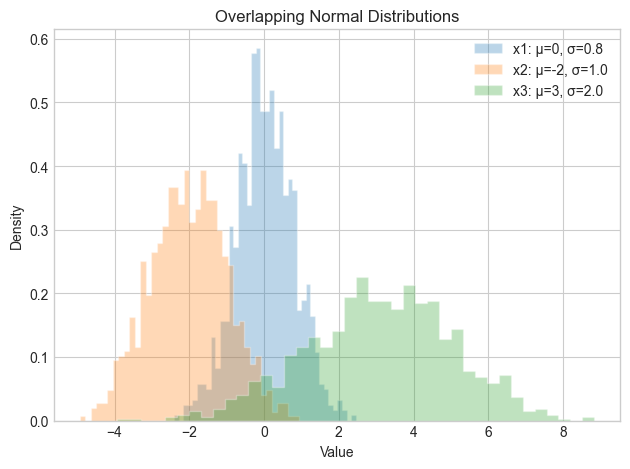

In [2]:
# 🎯 Generate three normal distributions
x1 = np.random.normal(loc=0, scale=0.8, size=1000)    # Centered at 0
x2 = np.random.normal(loc=-2, scale=1.0, size=1000)   # Centered at -2
x3 = np.random.normal(loc=3, scale=2.0, size=1000)    # Centered at 3

# ⚙️ Histogram styling options
kwargs = dict(
    histtype='stepfilled',  # Filled histogram with outlined edges
    alpha=0.3,               # Transparency level (30%)
    density=True,           # Normalize to show probability density
    bins=40                 # Number of bins (intervals)
)

# 📈 Plot overlapping histograms
plt.hist(x1, **kwargs, label='x1: μ=0, σ=0.8')
plt.hist(x2, **kwargs, label='x2: μ=-2, σ=1.0')
plt.hist(x3, **kwargs, label='x3: μ=3, σ=2.0')

# 🖼️ Add labels and legend
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Overlapping Normal Distributions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


If you would like to simply compute the histogram (that is, count the number of points in a given bin) and not display it, the **np.histogram()** function is available:



In [9]:
counts, bin_edges = np.histogram(data, bins=5)
print(counts)

[  9 121 466 337  67]


# Two-Dimensional Histograms and Binnings

Just as we create histograms in one dimension by dividing the number-line into bins, we can also create histograms in two-dimensions by dividing points among two-dimensional bins. We'll take a brief look at several ways to do this here. We'll start by defining some data—an **x** and **y** array drawn from a multivariate Gaussian distribution:



In [9]:
mean = [0, 0]                     # Mean vector → center at origin
cov = [[1, 1], [1, 2]]            # Covariance matrix → defines spread and correlation
x, y = np.random.multivariate_normal(mean, cov, 10000).T

## **plt.hist2d**: Two-dimensional histogram


One straightforward way to plot a two-dimensional histogram is to use Matplotlib's **plt.hist2d** function:



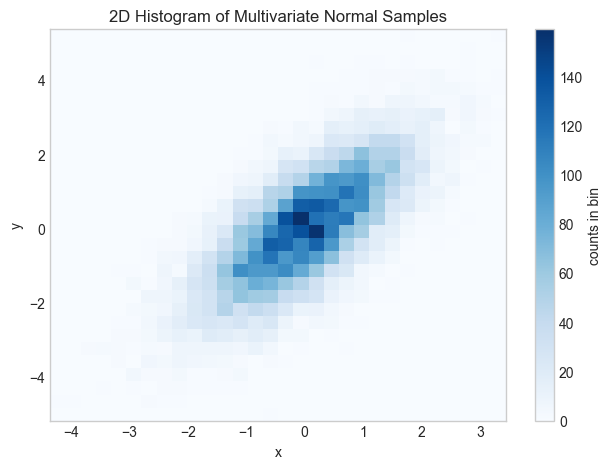

In [5]:
plt.hist2d(x, y, bins=30, cmap='Blues')
#-- To improve visibility ---
plt.xlabel("x")
plt.ylabel("y")
plt.title("2D Histogram of Multivariate Normal Samples")
plt.grid(True)
plt.tight_layout()
# --------------------------
cb = plt.colorbar()
cb.set_label('counts in bin')

Just as with **plt.hist**, plt.hist2d has a number of extra options to fine-tune the plot and the binning, which are nicely outlined in the function docstring. Further, just as **plt.hist** has a counterpart in **np.histogram**, **plt.hist2d** has a counterpart in **np.histogram2d**, which can be used as follows:



In [10]:
counts, xedges, yedges = np.histogram2d(x, y, bins=30)


For the generalization of this histogram binning in dimensions higher than two, see the **np.histogramdd** function.



## **plt.hexbin**: Hexagonal binnings


The two-dimensional histogram creates a tesselation of squares across the axes. Another natural shape for such a tesselation is the regular hexagon. For this purpose, Matplotlib provides the **plt.hexbin** routine, which will represents a two-dimensional dataset binned within a grid of hexagons:



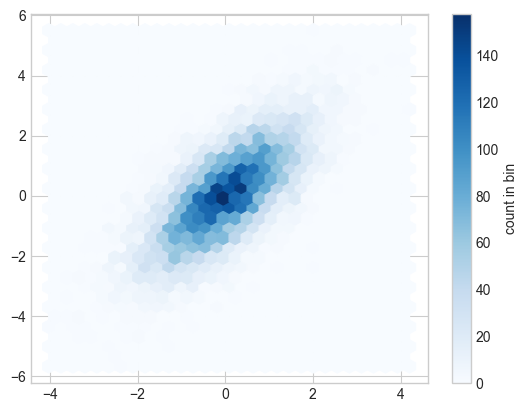

In [13]:
plt.hexbin(x, y, gridsize=30, cmap='Blues')
cb = plt.colorbar(label='count in bin')

**plt.hexbin** has a number of interesting options, including the ability to specify weights for each point, and to change the output in each bin to any NumPy aggregate (mean of weights, standard deviation of weights, etc.).

<div style="border: 2px solid red; padding: 10px; border-radius: 5px; background-color: #721c24; color: #f8d7da;">
<strong>!</strong> The next part on Kernel density estimation is just for illustration and not part of this course.</div>

## Kernel density estimation


Another common method of evaluating densities in multiple dimensions is *kernel density estimation* (KDE). For now we'll simply mention that KDE can be thought of as a way to "smear out" the points in space and add up the result to obtain a smooth function. One extremely quick and simple KDE implementation exists in the **scipy.stats** package. Here is a quick example of using the KDE on this data:

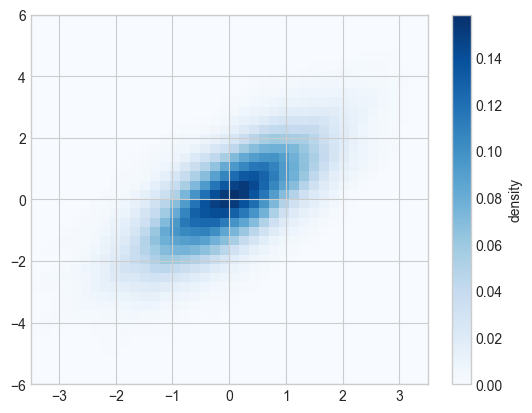

In [14]:
from scipy.stats import gaussian_kde

# fit an array of size [Ndim, Nsamples]
data = np.vstack([x, y])
kde = gaussian_kde(data)

# evaluate on a regular grid
xgrid = np.linspace(-3.5, 3.5, 40)
ygrid = np.linspace(-6, 6, 40)
Xgrid, Ygrid = np.meshgrid(xgrid, ygrid)
Z = kde.evaluate(np.vstack([Xgrid.ravel(), Ygrid.ravel()]))

# Plot the result as an image
plt.imshow(Z.reshape(Xgrid.shape),
           origin='lower', aspect='auto',
           extent=[-3.5, 3.5, -6, 6],
           cmap='Blues')
cb = plt.colorbar()
cb.set_label("density")

KDE has a smoothing length that effectively slides the knob between detail and smoothness (one example of the ubiquitous bias–variance trade-off). The literature on choosing an appropriate smoothing length is vast: **gaussian_kde** uses a rule-of-thumb to attempt to find a nearly optimal smoothing length for the input data.

Other KDE implementations are available within the SciPy ecosystem, each with its own strengths and weaknesses; see, for example, **sklearn.neighbors.KernelDensity** and **statsmodels.nonparametric.kernel_density.KDEMultivariate**. For visualizations based on KDE, using Matplotlib tends to be overly verbose. The Seaborn library, discussed in Visualization With Seaborn, provides a much more terse API for creating KDE-based visualizations.